In [1]:
import numpy as np
%pip install lime
import lime
from tokenizers import Tokenizer
from collections import OrderedDict
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path
import itertools
from datasets import concatenate_datasets

root = Path.cwd().parent
sys.path.insert(0, str(root))

import Project1


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
dataset = load_dataset("cardiffnlp/tweet_eval", "stance_climate")
dataset = dataset.map(lambda x: {"text": x["text"].replace(" #SemST", "")})

In [3]:
# feature representation

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class BagOfWords(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        vector = np.zeros(len(self))
        for token_id in self.tokenizer.encode(x).ids:
            vector[token_id] += 1
        return vector

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

class tfidf(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        self.dataset = dataset['train']
        self.idf = self._compute_idf()

    def _compute_idf(self) -> 'np.array':
        num_documents = len(self.dataset)
        df = np.zeros(len(self.tokenizer.get_vocab()))

        for example in self.dataset:
            unique_token_ids = set(self.tokenizer.encode(example['text']).ids)
            for token_id in unique_token_ids:
                df[token_id] += 1

        idf = np.log((num_documents + 1) / (df + 1)) + 1
        return idf

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        tf_vector = np.zeros(len(self))
        token_ids = self.tokenizer.encode(x).ids

        for token_id in token_ids:
            tf_vector[token_id] += 1

        if len(token_ids) > 0:
            tf_vector /= len(token_ids)

        tfidf_vector = tf_vector * self.idf
        return tfidf_vector

In [4]:
#tokenizer
vocab_size = 1000
min_frequency = 2
comb_dataset = concatenate_datasets([dataset["train"], dataset["validation"]])
corpus = [text for text in comb_dataset["text"]]
tokenizer = Project1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
token_indicator_encoder = TokenIndicator(tokenizer)

In [5]:
# cross-validation
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        Project1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(comb_dataset["text"], comb_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

In [6]:
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 

In [7]:
# classifiers
logistic_model = Project1.loglin.fit(my_cross_validation_sets[0][0]["training"], token_indicator_encoder, save_to=None)



/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [8]:
outcome_space_abortion = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_atheism = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_climate = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_feminist = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_hillary = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])

In [9]:
classifiers = OrderedDict()

In [10]:
token_indicator_encoder = TokenIndicator(tokenizer)
bow_encoder = BagOfWords(tokenizer)
tfidf_encoder = tfidf(tokenizer)

In [11]:
classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    classifiers['logistic_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWar

In [12]:
classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    classifiers['mlp_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.117 seconds
Dataloader done! Time taken: 0.009 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0477 | train acc: 0.4367 | val loss: 0.9872 | val acc: 0.6203
Epoch 02 | train loss: 0.9023 | train acc: 0.6962 | val loss: 0.9225 | val acc: 0.6076
Epoch 03 | train loss: 0.7947 | train acc: 0.7342 | val loss: 0.8870 | val acc: 0.5316
Epoch 04 | train loss: 0.7067 | train acc: 0.7785 | val loss: 0.8689 | val acc: 0.5316
Epoch 05 | train loss: 0.6342 | train acc: 0.8196 | val loss: 0.8586 | val acc: 0.5570
Epoch 06 | train loss: 0.5681 | train acc: 0.8861 | val loss: 0.8461 | val acc: 0.5949
Epoch 07 | train loss: 0.4995 | train acc: 0.9272 | val loss: 0.8325 | val acc: 0.5949
Epoch 08 | train loss: 0.4331 | train acc: 0.9494 | val loss: 0.8237 | val acc: 0.6076


/Users/mac/Documents/GitHub/NLP1/Project1/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/Users/mac/Documents/GitHub/NLP1/Project1/smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:923.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 09 | train loss: 0.3704 | train acc: 0.9652 | val loss: 0.8183 | val acc: 0.6076
Epoch 10 | train loss: 0.3144 | train acc: 0.9652 | val loss: 0.8172 | val acc: 0.6203
Epoch 11 | train loss: 0.2652 | train acc: 0.9684 | val loss: 0.8169 | val acc: 0.6203
Epoch 12 | train loss: 0.2250 | train acc: 0.9715 | val loss: 0.8191 | val acc: 0.6329
Epoch 13 | train loss: 0.1846 | train acc: 0.9715 | val loss: 0.8221 | val acc: 0.6329
Epoch 14 | train loss: 0.1578 | train acc: 0.9778 | val loss: 0.8346 | val acc: 0.6203
Epoch 15 | train loss: 0.1326 | train acc: 0.9778 | val loss: 0.8444 | val acc: 0.6329
Epoch 16 | train loss: 0.1114 | train acc: 0.9905 | val loss: 0.8560 | val acc: 0.6329
Epoch 17 | train loss: 0.0967 | train acc: 0.9905 | val loss: 0.8711 | val acc: 0.6329
Epoch 18 | train loss: 0.0833 | train acc: 0.9968 | val loss: 0.8828 | val acc: 0.6329
Epoch 19 | train loss: 0.0681 | train acc: 0.9968 | val loss: 0.8944 | val acc: 0.6329
Epoch 20 | train loss: 0.0616 | train acc: 

... (4 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0341 | train acc: 0.5158 | val loss: 0.9911 | val acc: 0.4810
Epoch 02 | train loss: 0.9033 | train acc: 0.6930 | val loss: 0.9110 | val acc: 0.5570
Epoch 03 | train loss: 0.8023 | train acc: 0.7437 | val loss: 0.8514 | val acc: 0.5570
Epoch 04 | train loss: 0.7146 | train acc: 0.8070 | val loss: 0.8109 | val acc: 0.5823
Epoch 05 | train loss: 0.6299 | train acc: 0.8829 | val loss: 0.7828 | val acc: 0.6076
Epoch 06 | train loss: 0.5586 | train acc: 0.9114 | val loss: 0.7617 | val acc: 0.6582
Epoch 07 | train loss: 0.4915 | train acc: 0.9367 | val loss: 0.7437 | val acc: 0.6456
Epoch 08 | train loss: 0.4250 | train acc: 0.9525 | val loss: 0.7296 | val acc: 0.6709
Epoch 09 | train loss: 0.3641 | train acc: 0.9557 | val loss: 0.7216 | val acc: 0.6709
Epoch 10 | train loss: 0.3082 | train acc: 0.9557 | val loss: 0.7090 | val acc: 0.6835
Epoch 11 | train loss: 0.2545 | train acc: 0.9652 | val loss: 0.7087 | val acc: 0.6835
Epoch 12 | train loss: 0.2129 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0597 | train acc: 0.5158 | val loss: 0.9872 | val acc: 0.5570
Epoch 02 | train loss: 0.9223 | train acc: 0.6582 | val loss: 0.8968 | val acc: 0.5570
Epoch 03 | train loss: 0.8144 | train acc: 0.7247 | val loss: 0.8237 | val acc: 0.5443
Epoch 04 | train loss: 0.7237 | train acc: 0.7785 | val loss: 0.7712 | val acc: 0.5570
Epoch 05 | train loss: 0.6467 | train acc: 0.8165 | val loss: 0.7306 | val acc: 0.5823
Epoch 06 | train loss: 0.5747 | train acc: 0.8797 | val loss: 0.6986 | val acc: 0.6076
Epoch 07 | train loss: 0.5018 | train acc: 0.9051 | val loss: 0.6762 | val acc: 0.6076
Epoch 08 | train loss: 0.4321 | train acc: 0.9272 | val loss: 0.6594 | val acc: 0.5949
Epoch 09 | train loss: 0.3686 | train acc: 0.9462 | val loss: 0.6514 | val acc: 0.6076
Epoch 10 | train loss: 0.3092 | train acc: 0.9525 | val loss: 0.6482 | val acc: 0.6203
Epoch 11 | train loss: 0.2665 | train acc: 0.9525 | val loss: 0.6486 | val acc: 0.6329
Epoch 12 | train loss: 0.2214 | train acc: 

In [13]:
classifiers['mlp2_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_indicator-enc/seed-{seed}"
    classifiers['mlp2_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.085 seconds
Dataloader done! Time taken: 0.004 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0528 | train acc: 0.5032 | val loss: 1.0044 | val acc: 0.4937
Epoch 02 | train loss: 0.9200 | train acc: 0.5854 | val loss: 0.9178 | val acc: 0.4810
Epoch 03 | train loss: 0.8024 | train acc: 0.5601 | val loss: 0.8767 | val acc: 0.5063
Epoch 04 | train loss: 0.7148 | train acc: 0.6139 | val loss: 0.8815 | val acc: 0.5063
Epoch 05 | train loss: 0.6339 | train acc: 0.7880 | val loss: 0.8864 | val acc: 0.5570
Epoch 06 | train loss: 0.5342 | train acc: 0.9019 | val loss: 0.8761 | val acc: 0.5949
Epoch 07 | train loss: 0.4135 | train acc: 0.9335 | val loss: 0.8694 | val acc: 0.5696
Epoch 08 | train loss: 0.2901 | train acc: 0.9462 | val loss: 0.8750 | val acc: 0.5823
Epoch 09 | train loss: 0.2013 | train acc: 0.9652 | val loss: 0.9108 | val acc: 0.5570
Epoch 10 | train loss: 0.1354 | train acc: 0.9684 | val loss: 0.9627 | val acc: 0.5696
Epoch 11 | train loss: 0.0916 | train acc: 0.9684 | val loss: 1.0188 | val acc: 0.5823
Epoch 12 | train loss: 0.0698 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0588 | train acc: 0.4589 | val loss: 1.0066 | val acc: 0.4557
Epoch 02 | train loss: 0.9447 | train acc: 0.6266 | val loss: 0.9177 | val acc: 0.5316
Epoch 03 | train loss: 0.8357 | train acc: 0.5601 | val loss: 0.8635 | val acc: 0.5316
Epoch 04 | train loss: 0.7599 | train acc: 0.5443 | val loss: 0.8558 | val acc: 0.5316
Epoch 05 | train loss: 0.6831 | train acc: 0.6994 | val loss: 0.8385 | val acc: 0.6076
Epoch 06 | train loss: 0.5890 | train acc: 0.8639 | val loss: 0.8252 | val acc: 0.6329
Epoch 07 | train loss: 0.4708 | train acc: 0.9209 | val loss: 0.8189 | val acc: 0.5823
Epoch 08 | train loss: 0.3509 | train acc: 0.9304 | val loss: 0.8258 | val acc: 0.5570
Epoch 09 | train loss: 0.2370 | train acc: 0.9557 | val loss: 0.8453 | val acc: 0.5696
Epoch 10 | train loss: 0.1627 | train acc: 0.9557 | val loss: 0.9020 | val acc: 0.5696
Epoch 11 | train loss: 0.1115 | train acc: 0.9620 | val loss: 0.9758 | val acc: 0.5696
Epoch 12 | train loss: 0.0779 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0622 | train acc: 0.4905 | val loss: 1.0049 | val acc: 0.5949
Epoch 02 | train loss: 0.9663 | train acc: 0.5570 | val loss: 0.9153 | val acc: 0.5696
Epoch 03 | train loss: 0.8659 | train acc: 0.5380 | val loss: 0.8288 | val acc: 0.5696
Epoch 04 | train loss: 0.7793 | train acc: 0.5411 | val loss: 0.7810 | val acc: 0.5696
Epoch 05 | train loss: 0.7029 | train acc: 0.6772 | val loss: 0.7600 | val acc: 0.6203
Epoch 06 | train loss: 0.6133 | train acc: 0.8956 | val loss: 0.7378 | val acc: 0.6962
Epoch 07 | train loss: 0.5064 | train acc: 0.8987 | val loss: 0.7148 | val acc: 0.6835
Epoch 08 | train loss: 0.3812 | train acc: 0.9335 | val loss: 0.6839 | val acc: 0.7342
Epoch 09 | train loss: 0.2704 | train acc: 0.9430 | val loss: 0.6750 | val acc: 0.7215
Epoch 10 | train loss: 0.1849 | train acc: 0.9462 | val loss: 0.7099 | val acc: 0.7342
Epoch 11 | train loss: 0.1261 | train acc: 0.9557 | val loss: 0.7444 | val acc: 0.7342
Epoch 12 | train loss: 0.0936 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0346 | train acc: 0.5443 | val loss: 0.9750 | val acc: 0.5063
Epoch 02 | train loss: 0.9261 | train acc: 0.5443 | val loss: 0.8747 | val acc: 0.5063
Epoch 03 | train loss: 0.8276 | train acc: 0.5443 | val loss: 0.7909 | val acc: 0.5063
Epoch 04 | train loss: 0.7431 | train acc: 0.5570 | val loss: 0.7320 | val acc: 0.5316
Epoch 05 | train loss: 0.6520 | train acc: 0.7152 | val loss: 0.6806 | val acc: 0.6076
Epoch 06 | train loss: 0.5404 | train acc: 0.8861 | val loss: 0.6535 | val acc: 0.6582
Epoch 07 | train loss: 0.4228 | train acc: 0.9082 | val loss: 0.6422 | val acc: 0.6456
Epoch 08 | train loss: 0.3055 | train acc: 0.9367 | val loss: 0.6324 | val acc: 0.6076
Epoch 09 | train loss: 0.2100 | train acc: 0.9494 | val loss: 0.6607 | val acc: 0.6203
Epoch 10 | train loss: 0.1525 | train acc: 0.9525 | val loss: 0.7052 | val acc: 0.6456
Epoch 11 | train loss: 0.1131 | train acc: 0.9525 | val loss: 0.7612 | val acc: 0.6456
Epoch 12 | train loss: 0.0891 | train acc: 

In [14]:
classifiers['logistic_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
    classifiers['logistic_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={'max_iter': 100}
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/

In [15]:
classifiers['mlp_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
    classifiers['mlp_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.089 seconds
Dataloader done! Time taken: 0.003 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1065 | train acc: 0.3133 | val loss: 1.0215 | val acc: 0.5949
Epoch 02 | train loss: 0.9409 | train acc: 0.6741 | val loss: 0.9472 | val acc: 0.5570
Epoch 03 | train loss: 0.8273 | train acc: 0.6962 | val loss: 0.8970 | val acc: 0.5696
Epoch 04 | train loss: 0.7352 | train acc: 0.7342 | val loss: 0.8676 | val acc: 0.5570
Epoch 05 | train loss: 0.6563 | train acc: 0.7785 | val loss: 0.8483 | val acc: 0.5696
Epoch 06 | train loss: 0.5839 | train acc: 0.8797 | val loss: 0.8334 | val acc: 0.6203
Epoch 07 | train loss: 0.5195 | train acc: 0.8956 | val loss: 0.8200 | val acc: 0.6076
Epoch 08 | train loss: 0.4531 | train acc: 0.9335 | val loss: 0.8060 | val acc: 0.5949
Epoch 09 | train loss: 0.3951 | train acc: 0.9557 | val loss: 0.7912 | val acc: 0.6329
Epoch 10 | train loss: 0.3306 | train acc: 0.9620 | val loss: 0.7816 | val acc: 0.6329
Epoch 11 | train loss: 0.2871 | train acc: 0.9589 | val loss: 0.7776 | val acc: 0.6456
Epoch 12 | train loss: 0.2366 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0883 | train acc: 0.3639 | val loss: 1.0227 | val acc: 0.4430
Epoch 02 | train loss: 0.9211 | train acc: 0.7089 | val loss: 0.9339 | val acc: 0.5190
Epoch 03 | train loss: 0.8013 | train acc: 0.8165 | val loss: 0.8781 | val acc: 0.5316
Epoch 04 | train loss: 0.7087 | train acc: 0.8481 | val loss: 0.8450 | val acc: 0.5823
Epoch 05 | train loss: 0.6346 | train acc: 0.8513 | val loss: 0.8262 | val acc: 0.5949
Epoch 06 | train loss: 0.5573 | train acc: 0.9114 | val loss: 0.8085 | val acc: 0.5949
Epoch 07 | train loss: 0.4851 | train acc: 0.9367 | val loss: 0.7955 | val acc: 0.6076
Epoch 08 | train loss: 0.4246 | train acc: 0.9430 | val loss: 0.7855 | val acc: 0.6076
Epoch 09 | train loss: 0.3557 | train acc: 0.9462 | val loss: 0.7806 | val acc: 0.6076
Epoch 10 | train loss: 0.3038 | train acc: 0.9494 | val loss: 0.7852 | val acc: 0.6076
Epoch 11 | train loss: 0.2542 | train acc: 0.9525 | val loss: 0.7852 | val acc: 0.6203
Epoch 12 | train loss: 0.2124 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0851 | train acc: 0.4019 | val loss: 1.0152 | val acc: 0.5316
Epoch 02 | train loss: 0.9357 | train acc: 0.7500 | val loss: 0.9219 | val acc: 0.6203
Epoch 03 | train loss: 0.8267 | train acc: 0.7880 | val loss: 0.8549 | val acc: 0.6076
Epoch 04 | train loss: 0.7358 | train acc: 0.8133 | val loss: 0.8105 | val acc: 0.6203
Epoch 05 | train loss: 0.6548 | train acc: 0.8291 | val loss: 0.7810 | val acc: 0.6329
Epoch 06 | train loss: 0.5819 | train acc: 0.9019 | val loss: 0.7599 | val acc: 0.6329
Epoch 07 | train loss: 0.5091 | train acc: 0.9272 | val loss: 0.7418 | val acc: 0.6456
Epoch 08 | train loss: 0.4452 | train acc: 0.9241 | val loss: 0.7263 | val acc: 0.6835
Epoch 09 | train loss: 0.3841 | train acc: 0.9589 | val loss: 0.7173 | val acc: 0.6835
Epoch 10 | train loss: 0.3231 | train acc: 0.9525 | val loss: 0.7096 | val acc: 0.6835
Epoch 11 | train loss: 0.2768 | train acc: 0.9557 | val loss: 0.7089 | val acc: 0.6709
Epoch 12 | train loss: 0.2317 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0567 | train acc: 0.4430 | val loss: 0.9763 | val acc: 0.5063
Epoch 02 | train loss: 0.9086 | train acc: 0.6551 | val loss: 0.8773 | val acc: 0.5316
Epoch 03 | train loss: 0.7930 | train acc: 0.7595 | val loss: 0.8074 | val acc: 0.5443
Epoch 04 | train loss: 0.7088 | train acc: 0.7722 | val loss: 0.7603 | val acc: 0.5823
Epoch 05 | train loss: 0.6333 | train acc: 0.8354 | val loss: 0.7255 | val acc: 0.5570
Epoch 06 | train loss: 0.5614 | train acc: 0.8892 | val loss: 0.7002 | val acc: 0.5949
Epoch 07 | train loss: 0.4896 | train acc: 0.9177 | val loss: 0.6842 | val acc: 0.5823
Epoch 08 | train loss: 0.4194 | train acc: 0.9399 | val loss: 0.6729 | val acc: 0.5823
Epoch 09 | train loss: 0.3612 | train acc: 0.9462 | val loss: 0.6677 | val acc: 0.5696
Epoch 10 | train loss: 0.3001 | train acc: 0.9525 | val loss: 0.6696 | val acc: 0.5823
Epoch 11 | train loss: 0.2579 | train acc: 0.9525 | val loss: 0.6737 | val acc: 0.5949
Epoch 12 | train loss: 0.2148 | train acc: 

In [16]:
classifiers['mlp2_bow-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_bow-enc/seed-{seed}"
    classifiers['mlp2_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.084 seconds
Dataloader done! Time taken: 0.004 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0559 | train acc: 0.3987 | val loss: 1.0071 | val acc: 0.4937
Epoch 02 | train loss: 0.9323 | train acc: 0.6646 | val loss: 0.9262 | val acc: 0.5696
Epoch 03 | train loss: 0.8204 | train acc: 0.6646 | val loss: 0.8800 | val acc: 0.5190
Epoch 04 | train loss: 0.7392 | train acc: 0.5791 | val loss: 0.8803 | val acc: 0.5190
Epoch 05 | train loss: 0.6794 | train acc: 0.7152 | val loss: 0.8752 | val acc: 0.6456
Epoch 06 | train loss: 0.5885 | train acc: 0.8576 | val loss: 0.8603 | val acc: 0.6456
Epoch 07 | train loss: 0.4831 | train acc: 0.8639 | val loss: 0.8317 | val acc: 0.6203
Epoch 08 | train loss: 0.3692 | train acc: 0.9241 | val loss: 0.8058 | val acc: 0.6962
Epoch 09 | train loss: 0.2571 | train acc: 0.9525 | val loss: 0.8202 | val acc: 0.6456
Epoch 10 | train loss: 0.1728 | train acc: 0.9589 | val loss: 0.8361 | val acc: 0.6709
Epoch 11 | train loss: 0.1195 | train acc: 0.9652 | val loss: 0.8740 | val acc: 0.6835
Epoch 12 | train loss: 0.0835 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0642 | train acc: 0.4557 | val loss: 0.9960 | val acc: 0.5316
Epoch 02 | train loss: 0.9270 | train acc: 0.6835 | val loss: 0.8969 | val acc: 0.5190
Epoch 03 | train loss: 0.8179 | train acc: 0.6582 | val loss: 0.8510 | val acc: 0.5570
Epoch 04 | train loss: 0.7379 | train acc: 0.5791 | val loss: 0.8530 | val acc: 0.5696
Epoch 05 | train loss: 0.6674 | train acc: 0.7152 | val loss: 0.8371 | val acc: 0.5570
Epoch 06 | train loss: 0.5707 | train acc: 0.9082 | val loss: 0.8173 | val acc: 0.5823
Epoch 07 | train loss: 0.4445 | train acc: 0.9209 | val loss: 0.8049 | val acc: 0.5823
Epoch 08 | train loss: 0.3287 | train acc: 0.9399 | val loss: 0.8229 | val acc: 0.5823
Epoch 09 | train loss: 0.2273 | train acc: 0.9430 | val loss: 0.8626 | val acc: 0.5696
Epoch 10 | train loss: 0.1515 | train acc: 0.9557 | val loss: 0.9276 | val acc: 0.5570
Epoch 11 | train loss: 0.1048 | train acc: 0.9589 | val loss: 1.0026 | val acc: 0.5570
Epoch 12 | train loss: 0.0785 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0638 | train acc: 0.5000 | val loss: 0.9949 | val acc: 0.5696
Epoch 02 | train loss: 0.9537 | train acc: 0.5285 | val loss: 0.8940 | val acc: 0.5696
Epoch 03 | train loss: 0.8437 | train acc: 0.5285 | val loss: 0.8117 | val acc: 0.5696
Epoch 04 | train loss: 0.7449 | train acc: 0.5823 | val loss: 0.7759 | val acc: 0.5696
Epoch 05 | train loss: 0.6540 | train acc: 0.7627 | val loss: 0.7589 | val acc: 0.6582
Epoch 06 | train loss: 0.5500 | train acc: 0.8987 | val loss: 0.7406 | val acc: 0.6582
Epoch 07 | train loss: 0.4280 | train acc: 0.9146 | val loss: 0.7311 | val acc: 0.6456
Epoch 08 | train loss: 0.3108 | train acc: 0.9367 | val loss: 0.7163 | val acc: 0.6456
Epoch 09 | train loss: 0.2157 | train acc: 0.9399 | val loss: 0.7439 | val acc: 0.6709
Epoch 10 | train loss: 0.1527 | train acc: 0.9525 | val loss: 0.7871 | val acc: 0.6582
Epoch 11 | train loss: 0.1127 | train acc: 0.9557 | val loss: 0.8373 | val acc: 0.6709
Epoch 12 | train loss: 0.0828 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0703 | train acc: 0.4177 | val loss: 0.9921 | val acc: 0.5063
Epoch 02 | train loss: 0.9515 | train acc: 0.6835 | val loss: 0.8746 | val acc: 0.5949
Epoch 03 | train loss: 0.8401 | train acc: 0.6772 | val loss: 0.7791 | val acc: 0.5316
Epoch 04 | train loss: 0.7688 | train acc: 0.5759 | val loss: 0.7316 | val acc: 0.5316
Epoch 05 | train loss: 0.6931 | train acc: 0.7532 | val loss: 0.6894 | val acc: 0.6582
Epoch 06 | train loss: 0.5956 | train acc: 0.8829 | val loss: 0.6682 | val acc: 0.5949
Epoch 07 | train loss: 0.4885 | train acc: 0.9146 | val loss: 0.6544 | val acc: 0.5949
Epoch 08 | train loss: 0.3714 | train acc: 0.9367 | val loss: 0.6445 | val acc: 0.6456
Epoch 09 | train loss: 0.2585 | train acc: 0.9430 | val loss: 0.6685 | val acc: 0.6203
Epoch 10 | train loss: 0.1820 | train acc: 0.9494 | val loss: 0.7107 | val acc: 0.6203
Epoch 11 | train loss: 0.1250 | train acc: 0.9557 | val loss: 0.7687 | val acc: 0.5949
Epoch 12 | train loss: 0.0909 | train acc: 

In [17]:
classifiers['logistic_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_tfidf-enc/seed-{seed}"
    classifiers['logistic_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=tfidf_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/

In [18]:
classifiers['mlp_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_tfidf-enc/seed-{seed}"
    classifiers['mlp_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=tfidf(tokenizer),
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.099 seconds
Dataloader done! Time taken: 0.003 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0879 | train acc: 0.4241 | val loss: 1.0760 | val acc: 0.4304
Epoch 02 | train loss: 1.0623 | train acc: 0.4241 | val loss: 1.0576 | val acc: 0.4304
Epoch 03 | train loss: 1.0352 | train acc: 0.4241 | val loss: 1.0362 | val acc: 0.4430
Epoch 04 | train loss: 1.0041 | train acc: 0.5095 | val loss: 1.0114 | val acc: 0.5443
Epoch 05 | train loss: 0.9668 | train acc: 0.8228 | val loss: 0.9837 | val acc: 0.5823
Epoch 06 | train loss: 0.9272 | train acc: 0.9019 | val loss: 0.9545 | val acc: 0.5696
Epoch 07 | train loss: 0.8817 | train acc: 0.8196 | val loss: 0.9264 | val acc: 0.5190
Epoch 08 | train loss: 0.8357 | train acc: 0.7658 | val loss: 0.9004 | val acc: 0.5190
Epoch 09 | train loss: 0.7934 | train acc: 0.7025 | val loss: 0.8781 | val acc: 0.5063
Epoch 10 | train loss: 0.7477 | train acc: 0.6994 | val loss: 0.8598 | val acc: 0.5190
Epoch 11 | train loss: 0.7089 | train acc: 0.7278 | val loss: 0.8437 | val acc: 0.5190
Epoch 12 | train loss: 0.6714 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0898 | train acc: 0.4209 | val loss: 1.0766 | val acc: 0.4304
Epoch 02 | train loss: 1.0598 | train acc: 0.6994 | val loss: 1.0531 | val acc: 0.5190
Epoch 03 | train loss: 1.0289 | train acc: 0.8196 | val loss: 1.0261 | val acc: 0.6582
Epoch 04 | train loss: 0.9927 | train acc: 0.8766 | val loss: 0.9957 | val acc: 0.6329
Epoch 05 | train loss: 0.9543 | train acc: 0.8576 | val loss: 0.9631 | val acc: 0.6076
Epoch 06 | train loss: 0.9106 | train acc: 0.8259 | val loss: 0.9305 | val acc: 0.5949
Epoch 07 | train loss: 0.8675 | train acc: 0.7911 | val loss: 0.8997 | val acc: 0.5949
Epoch 08 | train loss: 0.8252 | train acc: 0.7627 | val loss: 0.8718 | val acc: 0.6076
Epoch 09 | train loss: 0.7811 | train acc: 0.7563 | val loss: 0.8485 | val acc: 0.6076
Epoch 10 | train loss: 0.7426 | train acc: 0.7373 | val loss: 0.8299 | val acc: 0.6076
Epoch 11 | train loss: 0.7068 | train acc: 0.7785 | val loss: 0.8147 | val acc: 0.6076
Epoch 12 | train loss: 0.6675 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0874 | train acc: 0.5285 | val loss: 1.0690 | val acc: 0.5696
Epoch 02 | train loss: 1.0611 | train acc: 0.5285 | val loss: 1.0467 | val acc: 0.5696
Epoch 03 | train loss: 1.0340 | train acc: 0.5316 | val loss: 1.0210 | val acc: 0.5696
Epoch 04 | train loss: 1.0033 | train acc: 0.5285 | val loss: 0.9911 | val acc: 0.5696
Epoch 05 | train loss: 0.9689 | train acc: 0.5348 | val loss: 0.9577 | val acc: 0.5696
Epoch 06 | train loss: 0.9279 | train acc: 0.5380 | val loss: 0.9228 | val acc: 0.5696
Epoch 07 | train loss: 0.8868 | train acc: 0.5696 | val loss: 0.8877 | val acc: 0.5696
Epoch 08 | train loss: 0.8427 | train acc: 0.5949 | val loss: 0.8552 | val acc: 0.5696
Epoch 09 | train loss: 0.8016 | train acc: 0.6297 | val loss: 0.8258 | val acc: 0.5696
Epoch 10 | train loss: 0.7617 | train acc: 0.6646 | val loss: 0.8003 | val acc: 0.5696
Epoch 11 | train loss: 0.7184 | train acc: 0.7437 | val loss: 0.7779 | val acc: 0.5823
Epoch 12 | train loss: 0.6815 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0730 | train acc: 0.4114 | val loss: 1.0534 | val acc: 0.4684
Epoch 02 | train loss: 1.0487 | train acc: 0.6203 | val loss: 1.0325 | val acc: 0.5949
Epoch 03 | train loss: 1.0228 | train acc: 0.8165 | val loss: 1.0084 | val acc: 0.5443
Epoch 04 | train loss: 0.9940 | train acc: 0.7816 | val loss: 0.9801 | val acc: 0.5063
Epoch 05 | train loss: 0.9592 | train acc: 0.6962 | val loss: 0.9481 | val acc: 0.5190
Epoch 06 | train loss: 0.9212 | train acc: 0.6772 | val loss: 0.9144 | val acc: 0.5063
Epoch 07 | train loss: 0.8796 | train acc: 0.6677 | val loss: 0.8810 | val acc: 0.5063
Epoch 08 | train loss: 0.8372 | train acc: 0.6614 | val loss: 0.8495 | val acc: 0.5190
Epoch 09 | train loss: 0.7955 | train acc: 0.6614 | val loss: 0.8207 | val acc: 0.5190
Epoch 10 | train loss: 0.7551 | train acc: 0.6835 | val loss: 0.7943 | val acc: 0.5063
Epoch 11 | train loss: 0.7164 | train acc: 0.7405 | val loss: 0.7721 | val acc: 0.5443
Epoch 12 | train loss: 0.6750 | train acc: 

In [19]:
classifiers['mlp2_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_tfidf-enc/seed-{seed}"
    classifiers['mlp2_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.102 seconds
Dataloader done! Time taken: 0.004 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0614 | train acc: 0.5253 | val loss: 1.0165 | val acc: 0.4937
Epoch 02 | train loss: 0.9482 | train acc: 0.6646 | val loss: 0.9371 | val acc: 0.5063
Epoch 03 | train loss: 0.8334 | train acc: 0.5823 | val loss: 0.8820 | val acc: 0.5063
Epoch 04 | train loss: 0.7295 | train acc: 0.5918 | val loss: 0.8755 | val acc: 0.5063
Epoch 05 | train loss: 0.6317 | train acc: 0.7658 | val loss: 0.8674 | val acc: 0.5823
Epoch 06 | train loss: 0.5280 | train acc: 0.8956 | val loss: 0.8588 | val acc: 0.5823
Epoch 07 | train loss: 0.4088 | train acc: 0.9146 | val loss: 0.8429 | val acc: 0.6076
Epoch 08 | train loss: 0.2959 | train acc: 0.9272 | val loss: 0.8349 | val acc: 0.6329
Epoch 09 | train loss: 0.2076 | train acc: 0.9399 | val loss: 0.8521 | val acc: 0.6456
Epoch 10 | train loss: 0.1428 | train acc: 0.9589 | val loss: 0.8879 | val acc: 0.6582
Epoch 11 | train loss: 0.1016 | train acc: 0.9684 | val loss: 0.9310 | val acc: 0.6582
Epoch 12 | train loss: 0.0758 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0893 | train acc: 0.3956 | val loss: 1.0337 | val acc: 0.5316
Epoch 02 | train loss: 0.9549 | train acc: 0.5506 | val loss: 0.9344 | val acc: 0.5316
Epoch 03 | train loss: 0.8324 | train acc: 0.5411 | val loss: 0.8707 | val acc: 0.5316
Epoch 04 | train loss: 0.7257 | train acc: 0.5696 | val loss: 0.8466 | val acc: 0.6076
Epoch 05 | train loss: 0.6352 | train acc: 0.8070 | val loss: 0.8362 | val acc: 0.6329
Epoch 06 | train loss: 0.5341 | train acc: 0.9209 | val loss: 0.8245 | val acc: 0.6076
Epoch 07 | train loss: 0.4092 | train acc: 0.9367 | val loss: 0.8319 | val acc: 0.6203
Epoch 08 | train loss: 0.2927 | train acc: 0.9462 | val loss: 0.8380 | val acc: 0.5823
Epoch 09 | train loss: 0.1981 | train acc: 0.9525 | val loss: 0.8830 | val acc: 0.5696
Epoch 10 | train loss: 0.1386 | train acc: 0.9620 | val loss: 0.9754 | val acc: 0.5696
Epoch 11 | train loss: 0.0969 | train acc: 0.9652 | val loss: 1.0565 | val acc: 0.5823
Epoch 12 | train loss: 0.0721 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0444 | train acc: 0.4399 | val loss: 0.9745 | val acc: 0.4557
Epoch 02 | train loss: 0.9196 | train acc: 0.6994 | val loss: 0.8604 | val acc: 0.6203
Epoch 03 | train loss: 0.8167 | train acc: 0.5665 | val loss: 0.8000 | val acc: 0.5696
Epoch 04 | train loss: 0.7306 | train acc: 0.6551 | val loss: 0.7852 | val acc: 0.6203
Epoch 05 | train loss: 0.6494 | train acc: 0.8703 | val loss: 0.7734 | val acc: 0.6835
Epoch 06 | train loss: 0.5412 | train acc: 0.8924 | val loss: 0.7541 | val acc: 0.6709
Epoch 07 | train loss: 0.4245 | train acc: 0.9177 | val loss: 0.7340 | val acc: 0.7089
Epoch 08 | train loss: 0.3124 | train acc: 0.9335 | val loss: 0.7255 | val acc: 0.6582
Epoch 09 | train loss: 0.2201 | train acc: 0.9525 | val loss: 0.7490 | val acc: 0.6835
Epoch 10 | train loss: 0.1535 | train acc: 0.9589 | val loss: 0.7778 | val acc: 0.6582
Epoch 11 | train loss: 0.1071 | train acc: 0.9589 | val loss: 0.8227 | val acc: 0.6456
Epoch 12 | train loss: 0.0799 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0430 | train acc: 0.5000 | val loss: 0.9688 | val acc: 0.5316
Epoch 02 | train loss: 0.9296 | train acc: 0.6013 | val loss: 0.8652 | val acc: 0.5063
Epoch 03 | train loss: 0.8250 | train acc: 0.5601 | val loss: 0.7814 | val acc: 0.5063
Epoch 04 | train loss: 0.7522 | train acc: 0.5601 | val loss: 0.7296 | val acc: 0.5190
Epoch 05 | train loss: 0.6734 | train acc: 0.6646 | val loss: 0.6861 | val acc: 0.5823
Epoch 06 | train loss: 0.5674 | train acc: 0.8797 | val loss: 0.6611 | val acc: 0.5949
Epoch 07 | train loss: 0.4425 | train acc: 0.9114 | val loss: 0.6533 | val acc: 0.5823
Epoch 08 | train loss: 0.3187 | train acc: 0.9335 | val loss: 0.6742 | val acc: 0.5823
Epoch 09 | train loss: 0.2192 | train acc: 0.9430 | val loss: 0.6933 | val acc: 0.5949
Epoch 10 | train loss: 0.1578 | train acc: 0.9462 | val loss: 0.7584 | val acc: 0.6076
Epoch 11 | train loss: 0.1094 | train acc: 0.9525 | val loss: 0.8541 | val acc: 0.5823
Epoch 12 | train loss: 0.0869 | train acc: 

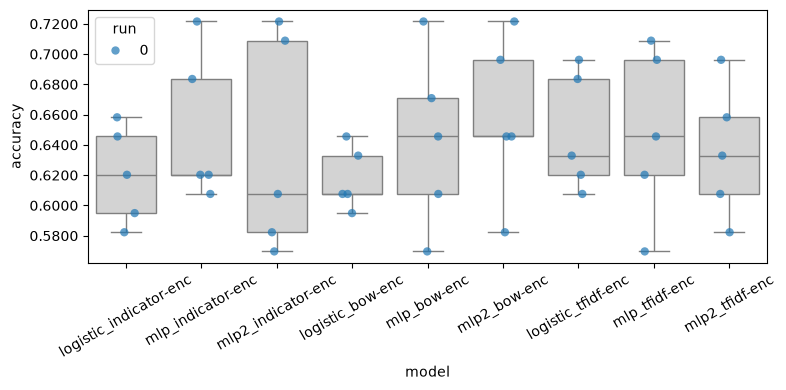

In [20]:
Project1.analysis.plot_box_and_points(Project1.analysis.make_data_frame(classifiers))

In [21]:
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])


A = logistic_indicator-enc, B = mlp_indicator-enc
P(A wins) = 0.1108
P(Tie)    = 0.0682
P(B wins) = 0.8209
Effect Size = 1.24

A = logistic_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.2945
P(Tie)    = 0.0851
P(B wins) = 0.6205
Effect Size = 0.46

A = mlp_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.6293
P(Tie)    = 0.1405
P(B wins) = 0.2302
Effect Size = -0.58


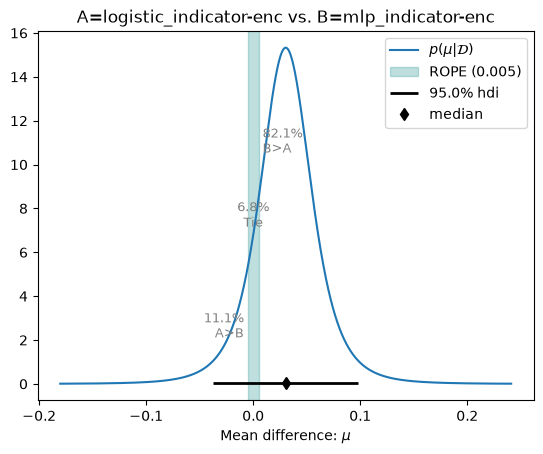

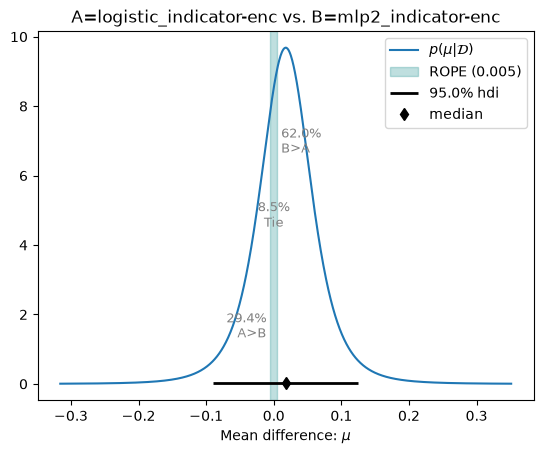

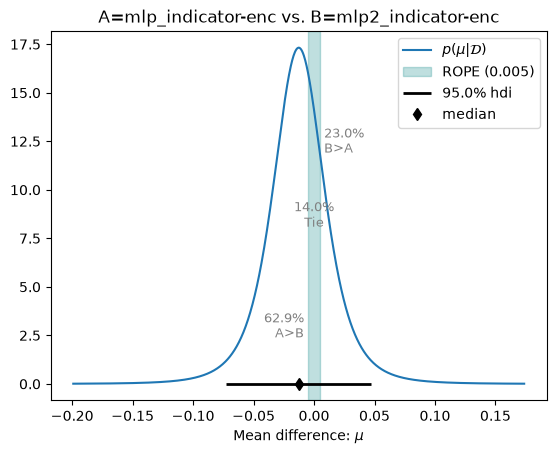

In [22]:
models = {
    "logistic_indicator-enc": get_all_measurements_for(
        classifiers, "logistic_indicator-enc"
    ).flatten(),

    "mlp_indicator-enc": get_all_measurements_for(
        classifiers, "mlp_indicator-enc"
    ).flatten(),

    "mlp2_indicator-enc": get_all_measurements_for(
        classifiers, "mlp2_indicator-enc"
    ).flatten()
}

rope = 0.005

# Compare every pair of models
for name_a, name_b in itertools.combinations(models.keys(), 2):

    posterior = Project1.analysis.BenavoliCorrelatedT(
        models[name_a],
        models[name_b],
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(rope)

    print(f"\nA = {name_a}, B = {name_b}")
    print(f"P(A wins) = {p_a:.4f}")
    print(f"P(Tie)    = {p_tie:.4f}")
    print(f"P(B wins) = {p_b:.4f}")
    print(f"Effect Size = {posterior.effect_size:.2f}")

    _ = posterior.plot(rope)

In [23]:

from pathlib import Path
import Project1.smlp as smlp
import Project1.smlp2 as smlp2

# Find saved checkpoints from your cross-validation
def find_checkpoints(model_name):
    folder = results_folder / model_name / "seed-0"

    checkpoints = sorted(
        path.with_suffix("")
        for path in folder.rglob("*.pt")
        if path.with_suffix(".json").exists()
    )

    if not checkpoints:
        raise FileNotFoundError(
            f"No saved model checkpoints found in {folder}"
        )

    return checkpoints


mlp_checkpoints = find_checkpoints("mlp_indicator-enc")
mlp2_checkpoints = find_checkpoints("mlp2_indicator-enc")

print("Original MLP checkpoints:")
for i, path in enumerate(mlp_checkpoints):
    print(i, path)

print("\nModified MLP checkpoints:")
for i, path in enumerate(mlp2_checkpoints):
    print(i, path)


Original MLP checkpoints:
0 results/mlp_indicator-enc/seed-0/fold-0/model
1 results/mlp_indicator-enc/seed-0/fold-1/model
2 results/mlp_indicator-enc/seed-0/fold-2/model
3 results/mlp_indicator-enc/seed-0/fold-3/model
4 results/mlp_indicator-enc/seed-0/fold-4/model

Modified MLP checkpoints:
0 results/mlp2_indicator-enc/seed-0/fold-0/model
1 results/mlp2_indicator-enc/seed-0/fold-1/model
2 results/mlp2_indicator-enc/seed-0/fold-2/model
3 results/mlp2_indicator-enc/seed-0/fold-3/model
4 results/mlp2_indicator-enc/seed-0/fold-4/model


In [24]:
# Select corresponding checkpoints from the same fold
fold = 0

mlp_model = smlp.load(
    str(mlp_checkpoints[fold]),
    device="cpu"
)

mlp2_model = smlp2.load2(
    str(mlp2_checkpoints[fold]),
    device="cpu"
)

mlp_model.eval()
mlp2_model.eval()

print("Both MLP models loaded successfully!")

Both MLP models loaded successfully!


In [25]:
# Log-linear
def logistic_predict(texts):
    return Project1.loglin.predict_probs(
        texts,
        logistic_model,
        token_indicator_encoder
    )

# Original MLP
def mlp_predict(texts):
    return Project1.smlp.predict_probs(
        texts,
        mlp_model,
        token_indicator_encoder
    )

# Modified MLP (two hidden layers)
def mlp2_predict(texts):
    return Project1.smlp2.predict_probs2(
        texts,
        mlp2_model,
        token_indicator_encoder
    )

# Models for LIME
models = {
    "Log-linear": logistic_predict,
    "Original MLP": mlp_predict,
    "Modified MLP": mlp2_predict
}

In [34]:
tweet_id = 157
test_text = dataset["test"][tweet_id]
print(test_text)
print("Original MLP:", mlp_predict(test_text))
print("Modified MLP:", mlp2_predict(test_text))
print("Log-linear:", logistic_predict(test_text))

{'text': 'The only thing "man made" about global warming is the false narrative. #WakeUpAmerica #boycottSanFrancisco #Election2016', 'label': 1}
Original MLP: [[0.45606908 0.2266685  0.31726235]
 [0.34859577 0.19868301 0.45272124]]
Modified MLP: [[0.41754168 0.15775761 0.42470077]
 [0.35332945 0.16967186 0.4769987 ]]
Log-linear: [[0.49655135 0.23450947 0.26893919]
 [0.19698896 0.20171904 0.601292  ]]



Tweet 1: What is the #energiewende agenda? Why are they not in the "de-carbonizer" camp?.  How long will you tolerate the lies? 
True class: favor

--- Log-linear ---
Prediction: favor
Probabilities: [0.1313 0.0019 0.8669]
Explanation: [(np.str_('carbonizer'), 0.33350352880701845), (np.str_('long'), 0.13687884349590781), (np.str_('energiewende'), -0.13155355941870375), (np.str_('in'), 0.09225816117511083), (np.str_('de'), -0.07754103052930933), (np.str_('How'), -0.06805738103631706), (np.str_('you'), -0.0617905006628361), (np.str_('will'), 0.05974221465334969), (np.str_('tolerate'), 0.05071462240329034), (np.str_('agenda'), 0.049272277383763136)]


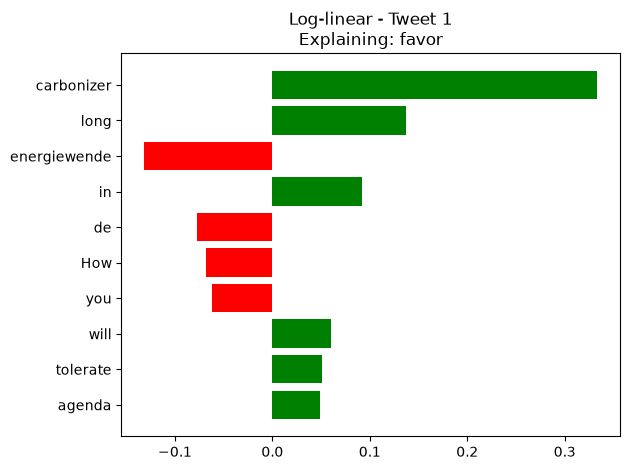


--- Original MLP ---
Prediction: favor
Probabilities: [0.3384 0.0047 0.6569]
Explanation: [(np.str_('carbonizer'), 0.23621436056865838), (np.str_('energiewende'), -0.08969036743363021), (np.str_('long'), 0.0547524527988509), (np.str_('agenda'), 0.05224492011311238), (np.str_('they'), -0.048921160185788765), (np.str_('What'), 0.039263800830439566), (np.str_('in'), 0.038813489263087045), (np.str_('are'), 0.03779654698837531), (np.str_('lies'), -0.0320042169070082), (np.str_('de'), -0.02271627863927302)]


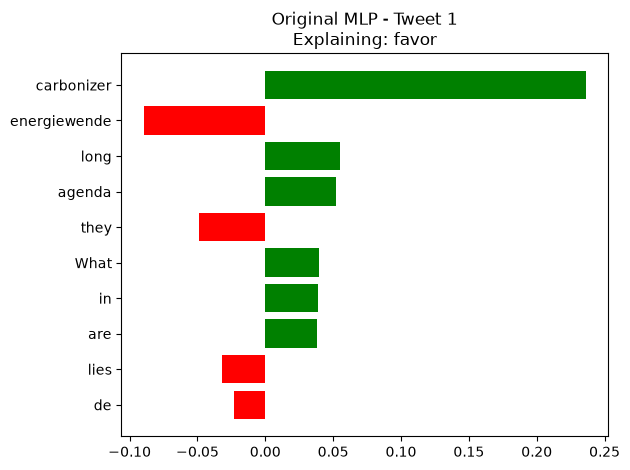


--- Modified MLP ---
Prediction: favor
Probabilities: [0.3767 0.0025 0.6208]
Explanation: [(np.str_('carbonizer'), 0.1316316407376362), (np.str_('they'), -0.05159252265625126), (np.str_('tolerate'), 0.04668635701060472), (np.str_('energiewende'), -0.04466954772222342), (np.str_('in'), 0.03438644350455113), (np.str_('What'), 0.028235744817924617), (np.str_('camp'), 0.021060883549547722), (np.str_('de'), -0.02055257987746244), (np.str_('long'), 0.020353183239940943), (np.str_('lies'), 0.014284152612668553)]


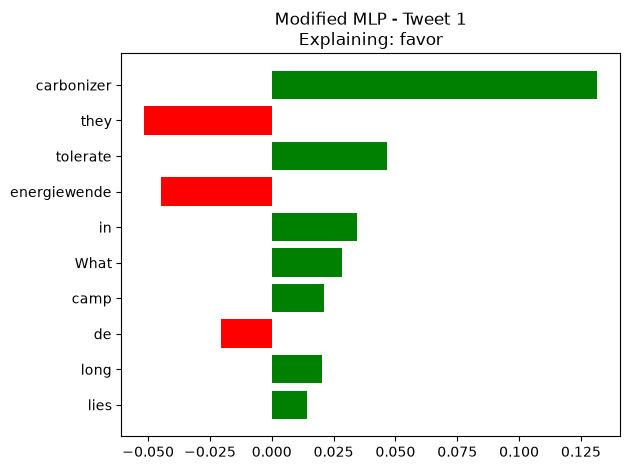


Tweet 8: It literarly just took me 10 minutes to get in a bus because an old lady just had to go in front of everyone...
True class: none

--- Log-linear ---
Prediction: favor
Probabilities: [0.0694 0.0297 0.9009]
Explanation: [(np.str_('lady'), -0.13536796493540307), (np.str_('in'), -0.05975259741919518), (np.str_('10'), -0.04577043907564428), (np.str_('front'), 0.045640099292783495), (np.str_('because'), -0.04198313587793902), (np.str_('bus'), 0.03251278333565001), (np.str_('minutes'), -0.031458966762754906), (np.str_('get'), -0.02548025864722159), (np.str_('just'), 0.023498261634702308), (np.str_('go'), 0.0185922329755259)]


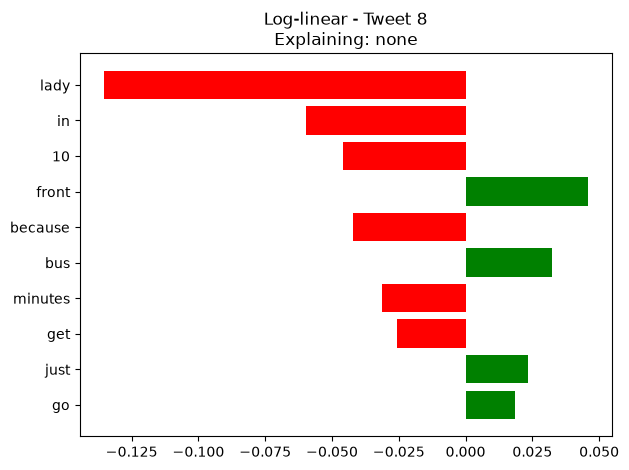


--- Original MLP ---
Prediction: favor
Probabilities: [0.2049 0.0197 0.7754]
Explanation: [(np.str_('lady'), -0.1042031557714831), (np.str_('10'), -0.06201727325200501), (np.str_('because'), -0.061338347759107154), (np.str_('just'), 0.034965792607285176), (np.str_('It'), 0.033007613393511506), (np.str_('in'), -0.02640087358829142), (np.str_('literarly'), -0.020786001800299804), (np.str_('of'), -0.014200045128442713), (np.str_('minutes'), -0.010718381068683367), (np.str_('me'), 0.008241205644131196)]


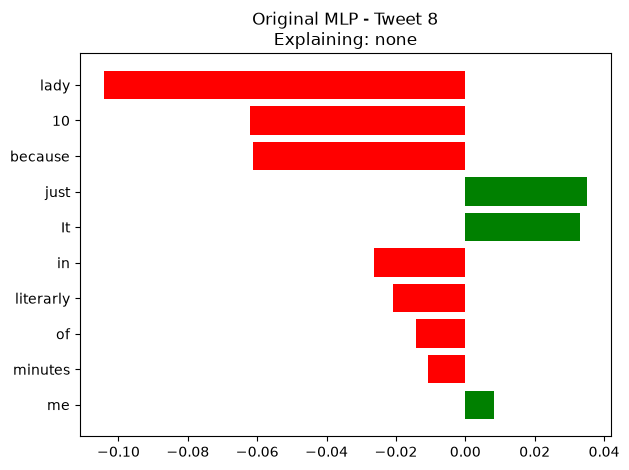


--- Modified MLP ---
Prediction: favor
Probabilities: [0.2604 0.0071 0.7325]
Explanation: [(np.str_('because'), -0.05699754873172486), (np.str_('minutes'), -0.05457847259391644), (np.str_('lady'), -0.04638804926245494), (np.str_('10'), -0.04112672958546213), (np.str_('just'), 0.03633162122582963), (np.str_('It'), 0.024160796869512495), (np.str_('in'), -0.023482451283052902), (np.str_('old'), 0.019950695853630185), (np.str_('everyone'), -0.015059983527759198), (np.str_('front'), 0.01362697793187385)]


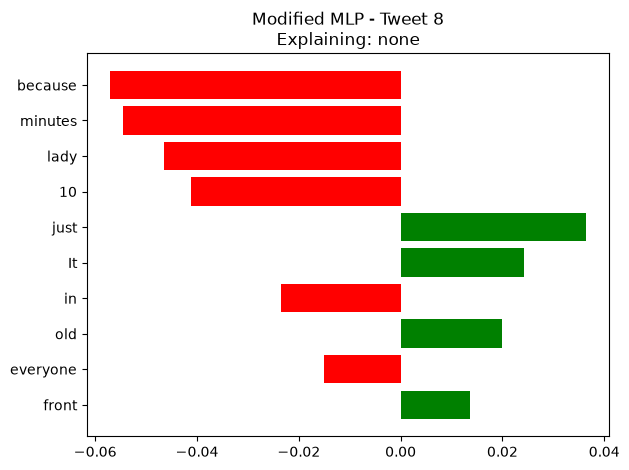


Tweet 157: The only thing "man made" about global warming is the false narrative. #WakeUpAmerica #boycottSanFrancisco #Election2016
True class: against

--- Log-linear ---
Prediction: none
Probabilities: [0.8507 0.0013 0.1479]
Explanation: [(np.str_('boycottSanFrancisco'), -0.02092040970779359), (np.str_('WakeUpAmerica'), -0.012884661511944489), (np.str_('is'), -0.011172896155432393), (np.str_('thing'), -0.008204554796862495), (np.str_('narrative'), -0.0074640902481949555), (np.str_('Election2016'), -0.004760114332735255), (np.str_('about'), -0.0027658247281629844), (np.str_('global'), -0.0025621609736868594), (np.str_('made'), -0.0021641115671610592), (np.str_('the'), -0.0019967220153775953)]


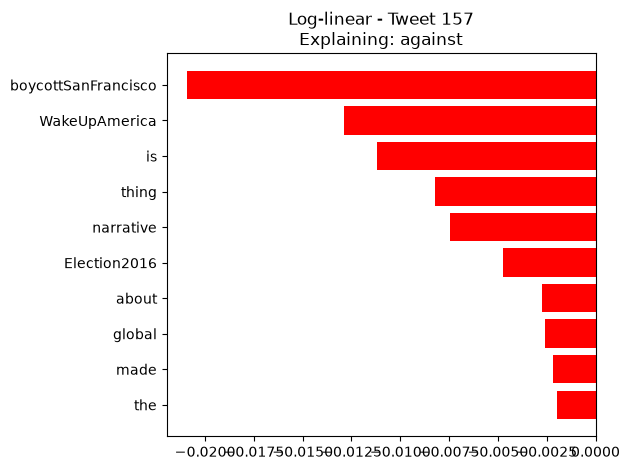


--- Original MLP ---
Prediction: none
Probabilities: [0.72   0.0034 0.2767]
Explanation: [(np.str_('boycottSanFrancisco'), -0.02630278229608494), (np.str_('WakeUpAmerica'), -0.02253388690005727), (np.str_('narrative'), -0.009781794985675458), (np.str_('made'), -0.008803203046892253), (np.str_('Election2016'), -0.00875726478607915), (np.str_('thing'), -0.006546033216946576), (np.str_('is'), -0.0059858367110590316), (np.str_('man'), -0.00454618793067299), (np.str_('the'), -0.0037482521210323344), (np.str_('The'), -0.003468665486502722)]


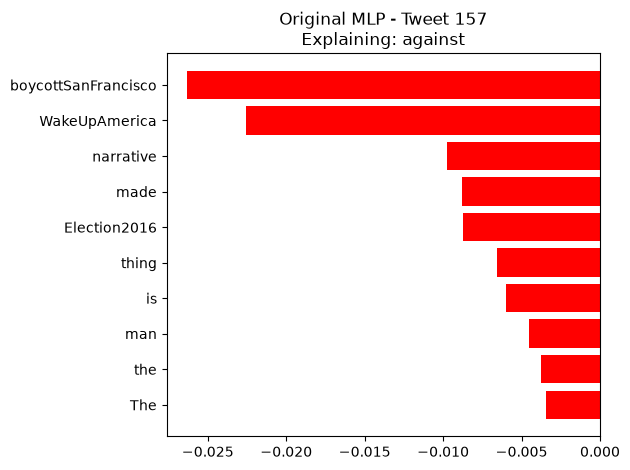


--- Modified MLP ---
Prediction: none
Probabilities: [0.6602 0.0008 0.339 ]
Explanation: [(np.str_('boycottSanFrancisco'), -0.008977956195005514), (np.str_('WakeUpAmerica'), -0.008385997878430486), (np.str_('Election2016'), -0.006748189470142898), (np.str_('thing'), -0.003980261028467083), (np.str_('made'), -0.003227713355652393), (np.str_('is'), -0.0026951378278519994), (np.str_('narrative'), -0.0025195139546327957), (np.str_('about'), -0.002137248714245282), (np.str_('man'), -0.0019744192125996066), (np.str_('The'), -0.0014025148024976722)]


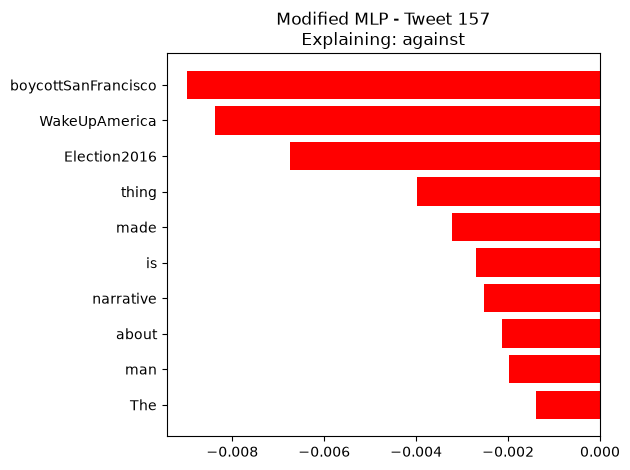

In [35]:
from lime.lime_text import LimeTextExplainer
import numpy as np
import matplotlib.pyplot as plt

class_names = dataset["train"].features["label"].names

explainer = LimeTextExplainer(
    class_names=class_names,
    random_state=42
)

models = {
    "Log-linear": logistic_predict,
    "Original MLP": mlp_predict,
    "Modified MLP": mlp2_predict
}

tweets = [1, 8, 157]

for tweet_id in tweets:

    example = dataset["test"][tweet_id]

    text = example["text"]
    true_label = int(example["label"])

    print(f"\n{'=' * 60}")
    print(f"Tweet {tweet_id}: {text}")
    print(f"True class: {class_names[true_label]}")

    for model_name, predict_fn in models.items():

        probabilities = predict_fn([text])[0]
        predicted_label = int(np.argmax(probabilities))

        # Explain the same target class across all models
        exp = explainer.explain_instance(
            text,
            predict_fn,
            num_features=10,
            num_samples=1000,
            labels=(true_label,)
        )

        print(f"\n--- {model_name} ---")
        print("Prediction:", class_names[predicted_label])
        print("Probabilities:", probabilities.round(4))
        print("Explanation:", exp.as_list(label=true_label))

        fig = exp.as_pyplot_figure(label=true_label)
        plt.title(
            f"{model_name} - Tweet {tweet_id}\n"
            f"Explaining: {class_names[true_label]}"
        )
        plt.tight_layout()
        plt.show()


In [28]:
# Collect cross-validation accuracy measurements
model_scores = {
    "Log-linear": get_all_measurements_for(
        classifiers, "logistic_indicator-enc"
    ).flatten(),

    "MLP": get_all_measurements_for(
        classifiers, "mlp_indicator-enc"
    ).flatten(),

    "Modified MLP": get_all_measurements_for(
        classifiers, "mlp2_indicator-enc"
    ).flatten()
}

# Check the shapes
for name, scores in model_scores.items():
    print(name, scores.shape)

# Bayesian comparisons
results = []

for name_a, name_b in itertools.combinations(model_scores.keys(), 2):

    scores_a = np.asarray(model_scores[name_a], dtype=float)
    scores_b = np.asarray(model_scores[name_b], dtype=float)

    assert scores_a.shape == scores_b.shape, (
        "The models must have the same number of paired measurements."
    )

    posterior = Project1.analysis.BenavoliCorrelatedT(
        scores_a,
        scores_b,
        runs=1,  # Change if you used repeated cross-validation
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(0.005)

    results.append({
        "Model A": name_a,
        "Model B": name_b,
        "P(A wins)": p_a,
        "P(Tie)": p_tie,
        "P(B wins)": p_b,
        "Effect Size": posterior.effect_size
    })

df = pd.DataFrame(results)

display(df.round(4))


Log-linear (5,)
MLP (5,)
Modified MLP (5,)


,Model A,Model B,P(A wins),P(Tie),P(B wins),Effect Size
0,Log-linear,MLP,0.1108,0.0682,0.8209,1.2418
1,Log-linear,Modified MLP,0.2945,0.0851,0.6205,0.4576
2,MLP,Modified MLP,0.6293,0.1405,0.2302,-0.5847


In [29]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rows = []
for sys_name, runs in classifiers.items():
    acc, prec, rec, f1 = [], [], [], []
    for r, run_data in enumerate(runs):
        for i, (fold, preds) in enumerate(run_data['predictions'].items()):
            gold = [y for _, y in my_cross_validation_sets[r][i]["validation"]]
            acc.append(accuracy_score(gold, preds))
            prec.append(precision_score(gold, preds, average="macro", zero_division=0))
            rec.append(recall_score(gold, preds, average="macro", zero_division=0))
            f1.append(f1_score(gold, preds, average="macro", zero_division=0))
    rows.append({
        "model": sys_name,
        "accuracy": np.mean(acc),
        "precision": np.mean(prec),
        "recall": np.mean(rec),
        "f1": np.mean(f1),
    })

metrics_df = pd.DataFrame(rows)
print(metrics_df.round(4).to_string(index=False))

                 model  accuracy  precision  recall     f1
logistic_indicator-enc    0.6203     0.5837  0.5053 0.5178
     mlp_indicator-enc    0.6506     0.5478  0.4929 0.4911
    mlp2_indicator-enc    0.6380     0.4645  0.4726 0.4613
      logistic_bow-enc    0.6177     0.5796  0.4863 0.4981
           mlp_bow-enc    0.6430     0.5349  0.4847 0.4855
          mlp2_bow-enc    0.6582     0.4803  0.4926 0.4828
    logistic_tfidf-enc    0.6481     0.5038  0.4687 0.4527
         mlp_tfidf-enc    0.6481     0.4740  0.4767 0.4672
        mlp2_tfidf-enc    0.6354     0.4615  0.4722 0.4595
